This is a rocketpy jupyter notebook

In [3]:
from rocketpy import Environment, Motor, Rocket, Flight

In [4]:
env = Environment(latitude=32.990254, longitude=-106.974998, elevation=1400)

import datetime

tomorrow = datetime.date.today() + datetime.timedelta(days=1)

env.set_date(
    (tomorrow.year, tomorrow.month, tomorrow.day, 12)
)  # Hour given in UTC time

env.set_atmospheric_model(type="Forecast", file="GFS")


Gravity Details

Acceleration of gravity at surface level:    9.7911 m/s²
Acceleration of gravity at  78.548 km (ASL): 9.5577 m/s²


Launch Site Details

Launch Date: 2026-11-07 12:00:00 UTC
Launch Site Latitude: 32.99025°
Launch Site Longitude: -106.97500°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 315468.64 W    3651938.65 N
Launch Site UTM zone: 13S
Launch Site Surface Elevation: 1471.5 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 78.548 km
Forecast Time Period: from 2026-10-30 03:00:00 to 2026-11-22 06:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 3.05 m/s
Surface Wind Direction: 17.64°
Surface Wind Heading: 197.64°
Surface Pressure: 855.08 hPa
Surface Temperature: 285.09 K
Surface Air Density: 1.045 kg/m³
Surface Speed of Sound: 338.48 m/s


Earth Model Details

Earth Radius at Launch 

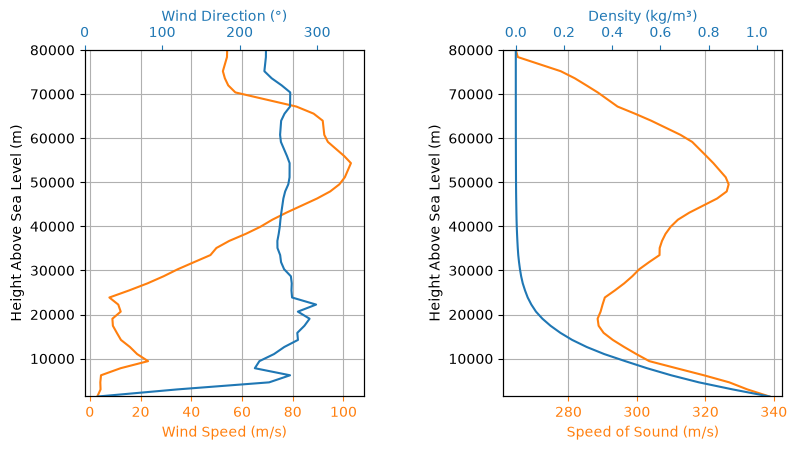

In [5]:
env.info()

In [6]:
from rocketpy import SolidMotor

test_motor = SolidMotor(
    thrust_source="motor_data/AeroTech_L1500T.eng",
    dry_mass=2.1952,
    dry_inertia=(0.125, 0.125, 0.002),
    center_of_dry_mass_position=0,
    grains_center_of_mass_position=0.397,
    burn_time=3.47,
    grain_number=5,
    grain_separation=5 / 1000,
    grain_density=1815,
    grain_outer_radius= 0.0331,
    grain_initial_inner_radius=0.015,
    grain_initial_height=0.12,
    nozzle_radius=0.03,
    throat_radius=0.01,
    interpolation_method="linear",
    nozzle_position=0,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

Nozzle Details
Nozzle Radius: 0.03 m
Nozzle Throat Radius: 0.01 m

Grain Details
Number of Grains: 5
Grain Spacing: 0.005 m
Grain Density: 1815 kg/m3
Grain Outer Radius: 0.0331 m
Grain Inner Radius: 0.015 m
Grain Height: 0.12 m
Grain Volume: 0.000 m3
Grain Mass: 0.596 kg

Motor Details
Total Burning Time: 3.47 s
Total Propellant Mass: 2.979 kg
Structural Mass Ratio: 0.424
Average Propellant Exhaust Velocity: 1696.438 m/s
Average Thrust: 1456.162 N
Maximum Thrust: 1704.286 N at 1.42 s after ignition.
Total Impulse: 5052.884 Ns



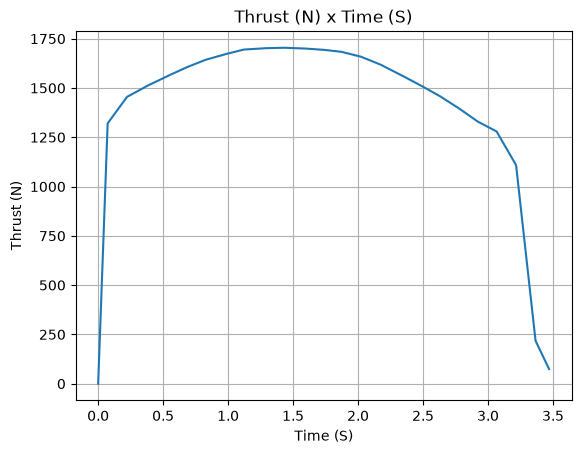

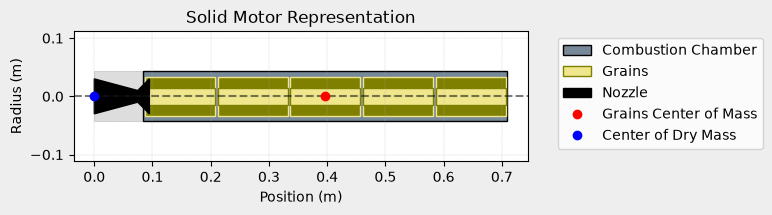

In [7]:
test_motor.info()
test_motor.draw()

In [8]:
proto1 = Rocket(
    radius=0.07,
    mass=5,
    inertia=(2.321, 2.321, 0.024),
    power_off_drag="data/drag_coeff.csv",
    power_on_drag="data/drag_coeff.csv",
    center_of_mass_without_motor=1,
    coordinate_system_orientation="tail_to_nose",
)

nose_cone = proto1.add_nose(
    length=0.6, kind="von karman", position=1
)

fin_set = proto1.add_trapezoidal_fins(
    n=4,
    root_chord=0.120,
    tip_chord=0.060,
    span=0.110,
    position=-1.04956,
    cant_angle=0,
    airfoil=None,
)

rail_buttons = proto1.set_rail_buttons(
    upper_button_position=0.3,
    lower_button_position=-0.8,
    angular_position=45,
)

main_chute = proto1.add_parachute(
    name="main",
    cd_s=10.0,
    trigger="apogee",
    sampling_rate=105,
    lag=1.5,
    noise=(0, 8.3, 0.5),
    radius=1,
    height=1.5,
    porosity=0.0432,
)

proto1.add_motor(test_motor, position=-1.15)


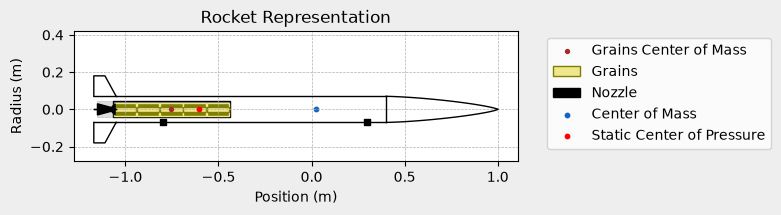

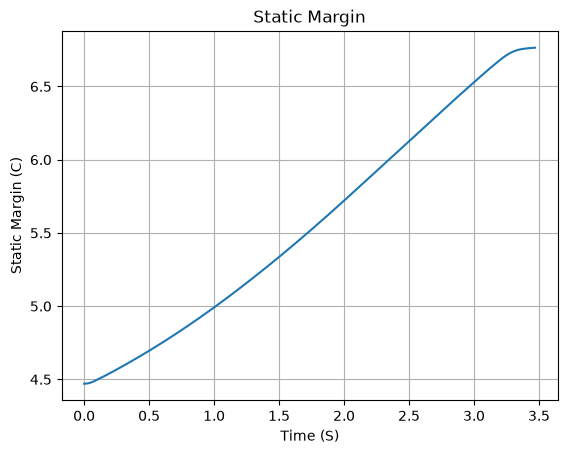

In [9]:
proto1.draw()
proto1.plots.static_margin()


Maximum Values

Maximum Speed: 416.496 m/s at 3.25 s
Maximum Mach Number: 1.241 Mach at 3.27 s
Maximum Reynolds Number: 3.233e+06 at 3.24 s
Maximum Dynamic Pressure: 8.431e+04 Pa at 3.24 s
Maximum Acceleration During Motor Burn: 166.976 m/s² at 1.28 s
Maximum Gs During Motor Burn: 17.027 g at 1.28 s
Maximum Acceleration After Motor Burn: 247.944 m/s² at 24.15 s
Maximum Gs After Motor Burn: 25.283 Gs at 24.15 s
Maximum Stability Margin: 7.231 c at 3.77 s
Maximum Upper Rail Button Normal Force: 0.892 N
Maximum Upper Rail Button Shear Force: 0.286 N
Maximum Lower Rail Button Normal Force: 4.497 N
Maximum Lower Rail Button Shear Force: 1.441 N

Initial Conditions

Initial time: 0.000 s
Position - x: 0.00 m | y: 0.00 m | z: 1471.47 m
Velocity - Vx: 0.00 m/s | Vy: 0.00 m/s | Vz: 0.00 m/s
Attitude (quaternions) - e0: 0.923 | e1: -0.040 | e2: 0.017 | e3: 0.382
Euler Angles - Spin φ : 45.00° | Nutation θ: -5.00° | Precession ψ: 0.00°
Angular Velocity - ω1: 0.00 rad/s | ω2: 0.00 rad/s | ω3: 0.0

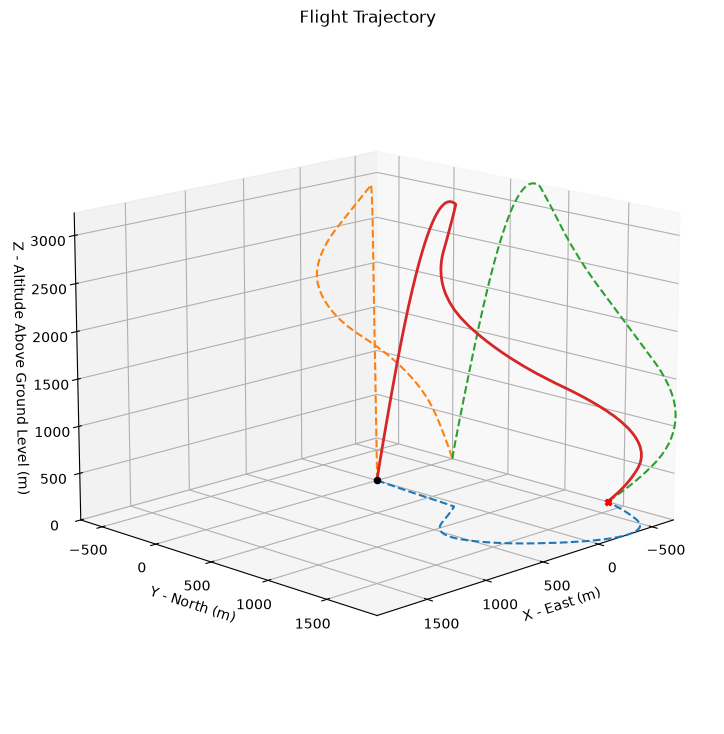



Trajectory Kinematic Plots



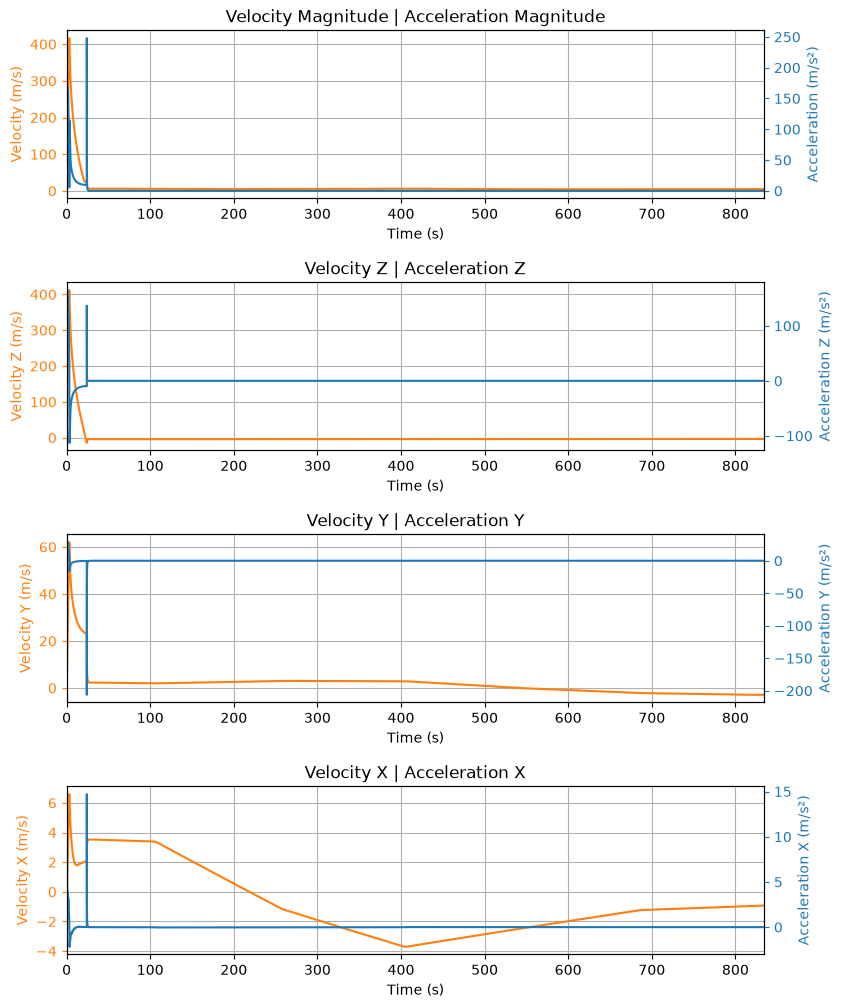



Angular Position Plots



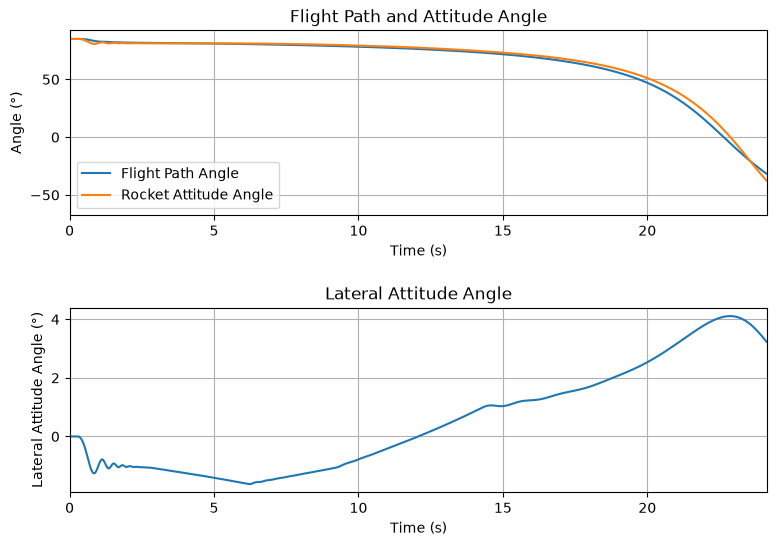



Path, Attitude and Lateral Attitude Angle Plots



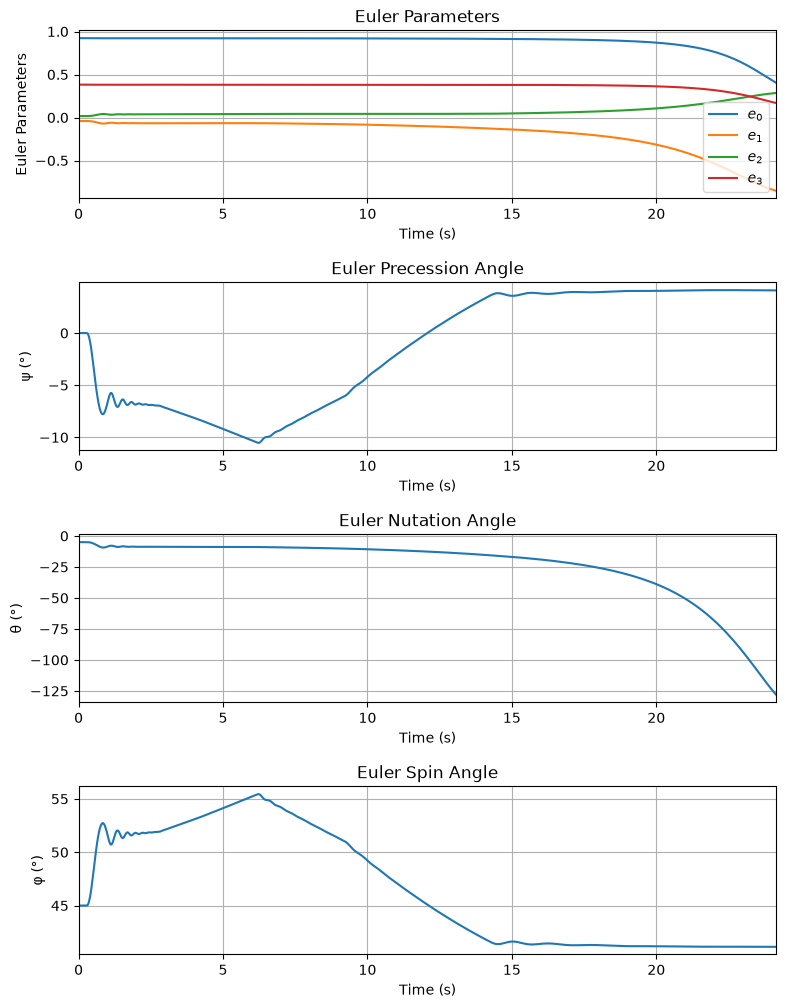



Trajectory Angular Velocity and Acceleration Plots



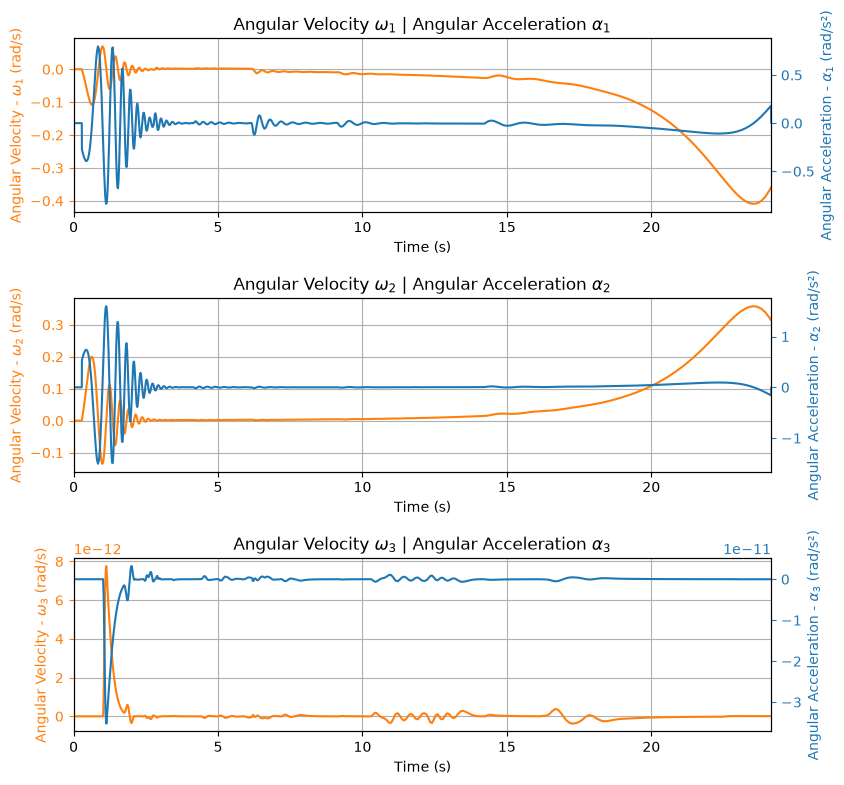



Aerodynamic Forces Plots



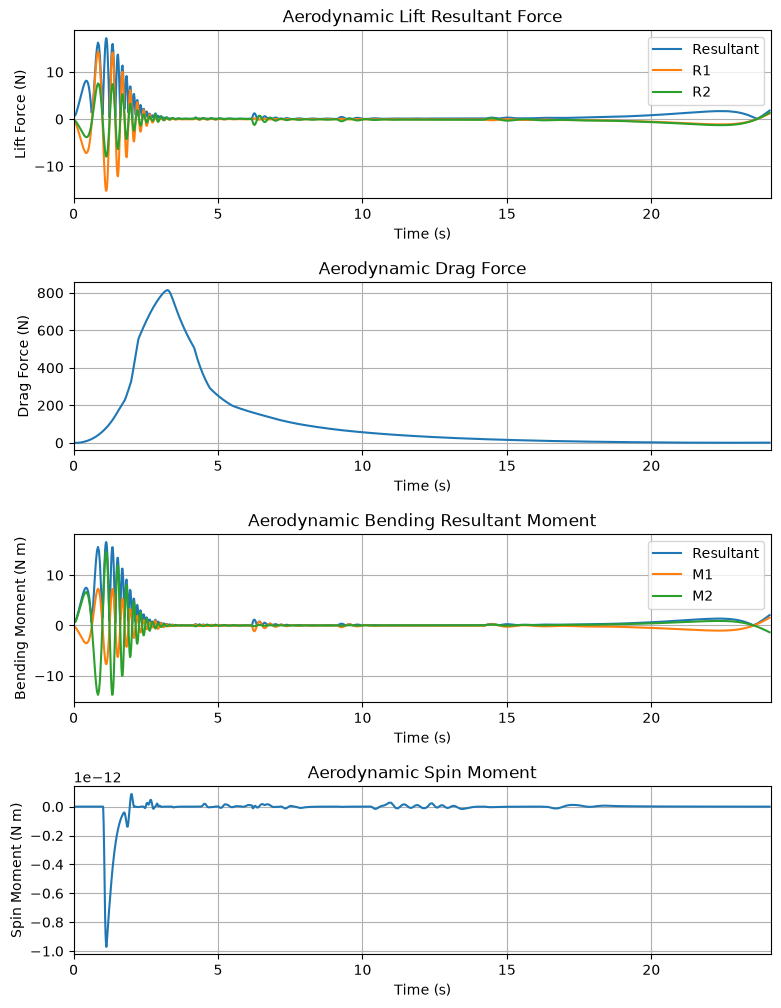

Rail button height not defined. Skipping bending moment plots.




Rail Buttons Bending Moments Plots



Rail Buttons Forces Plots



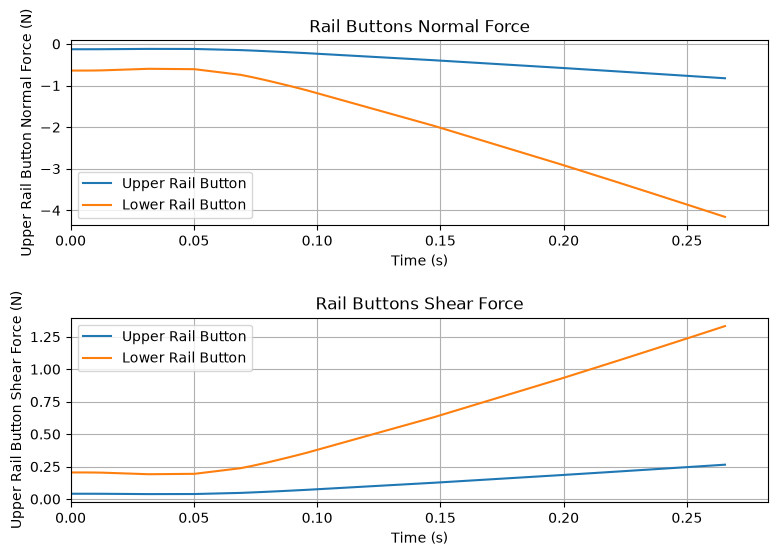



Trajectory Energy Plots



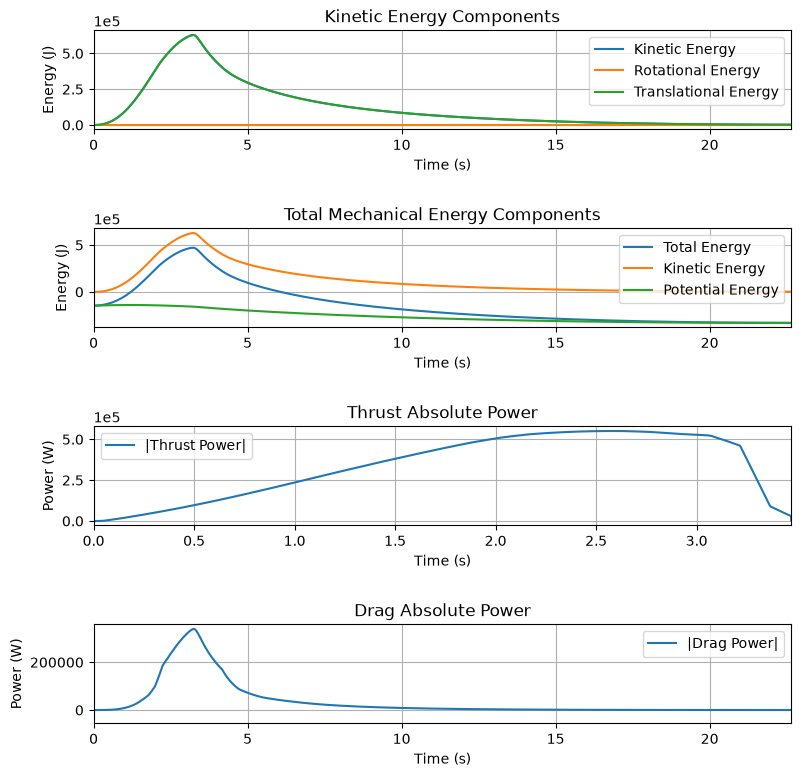



Trajectory Fluid Mechanics Plots



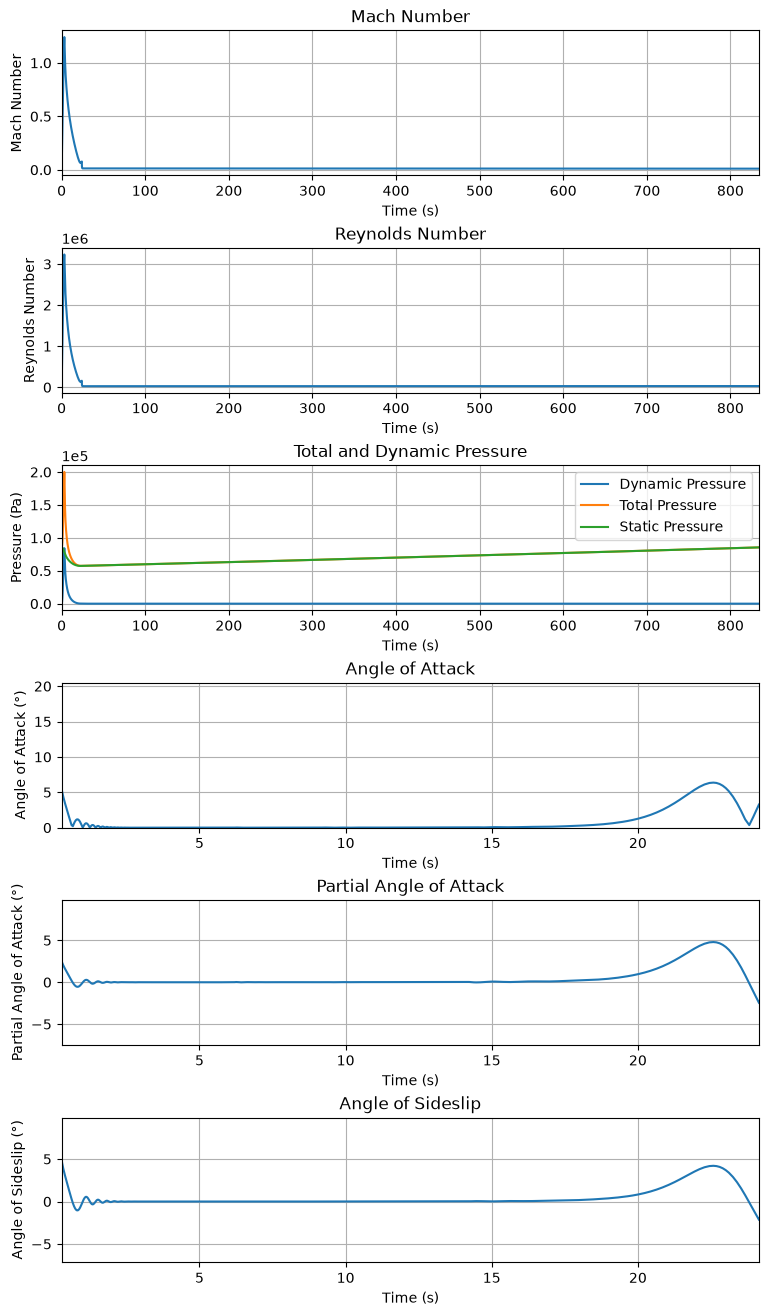



Trajectory Stability and Control Plots



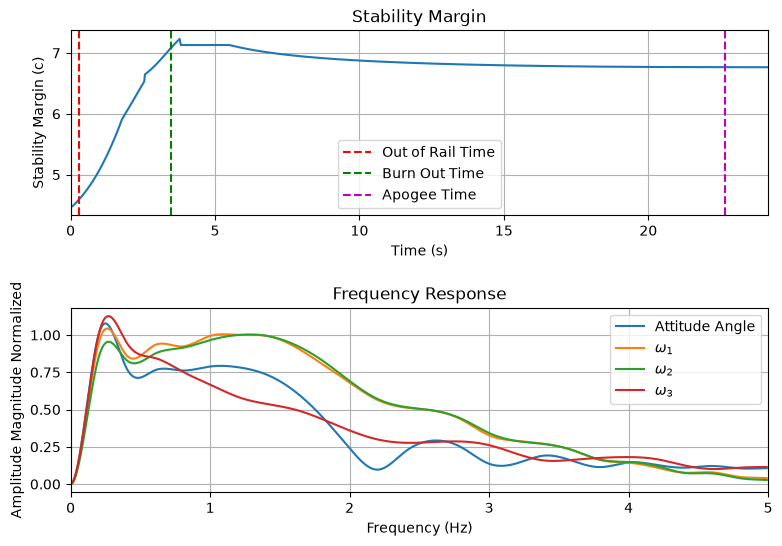



Rocket and Parachute Pressure Plots



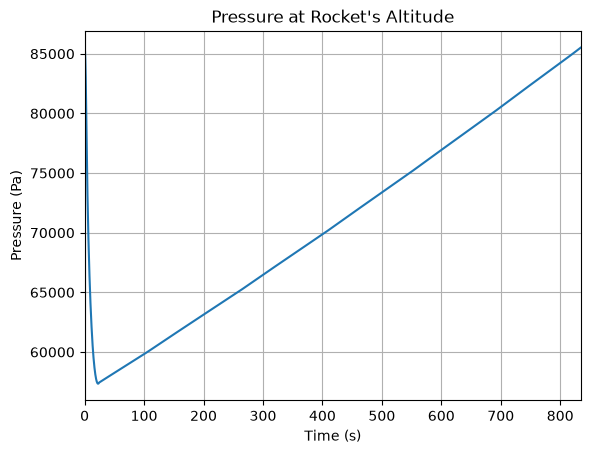

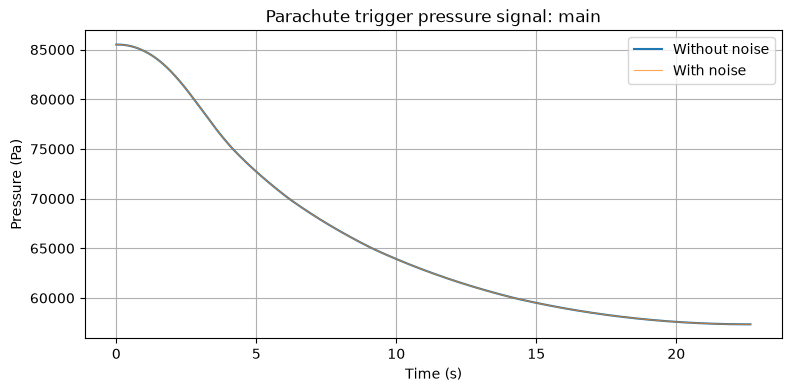


Apogee State

Apogee Time: 22.646 s
Apogee Altitude: 4703.187 m (ASL) | 3231.721 m (AGL)
Apogee Freestream Speed: 21.060 m/s
Apogee X position: 56.667 m
Apogee Y position: 708.824 m
Apogee latitude: 32.9966278°
Apogee longitude: -106.9743905°


In [10]:
test_flight = Flight(
    rocket=proto1, environment=env, rail_length=5.2, inclination=85, heading=0, max_time=1200
    )
test_flight.prints.maximum_values()
test_flight.all_info()
test_flight.prints.apogee_conditions()